# B1.2 共享会议室预约与空间利用业务场景挖掘（参考答案）
空白处按官方素材 M1~M4 补全；末尾两格为可视化（任务一要求“使用数据可视化技术展示分析结果”）。

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# 读取数据
bookings = pd.read_csv('meeting_bookings.csv', encoding='utf-8-sig')
rooms = pd.read_csv('meeting_rooms.csv', encoding='utf-8-sig')

# M1（1分）：数据准备
# 按booking_id去重，再排除已取消预约
clean = bookings.drop_duplicates(subset='booking_id').copy()
valid = clean[clean['status'] != '已取消'].copy()

print('数据准备结果')
print('去重后预约数：', len(clean))
print('有效预约数：', len(valid))

# M2（2分）：识别爽约高发时段
# 统计各时段的有效预约数、爽约数和爽约率，并按爽约率降序排列
valid['is_no_show'] = (valid['status'] == '爽约').astype(int)
slot_summary = (valid.groupby('time_slot')
                .agg(有效预约数=('booking_id', 'count'), 爽约数=('is_no_show', 'sum'), 爽约率=('is_no_show', 'mean'))
                .sort_values('爽约率', ascending=False))
slot_summary['爽约率'] = slot_summary['爽约率'].round(3)

print('\n各时段爽约情况')
print(slot_summary)


# M3（2分）：分析会议室容量匹配
# 只分析已使用预约，关联会议室容量，统计使用场次和平均座位利用率
used = valid[valid['status'] == '已使用'].merge(rooms, on='room_id', how='left')
used['seat_util'] = used["attendees"] / used["capacity"]
room_summary = (used.groupby(['room_id', 'room_name', 'capacity'])
                .agg(使用场次=('booking_id', 'count'), 平均参会人数=('attendees', 'mean'), 平均座位利用率=('seat_util', 'mean'))
                .reset_index().round(3))

print('\n各会议室空间利用情况')
print(room_summary)


# M4（1分）：输出空间匹配优化候选清单
# 筛选容量不少于12、实际使用不少于20场、平均座位利用率低于40%的会议室
candidates = room_summary[(room_summary['capacity'] >= 12) & (room_summary['使用场次'] >= 20) & (room_summary['平均座位利用率'] < 0.4)]

print('\n空间匹配优化候选清单')
print(candidates)

数据准备结果
去重后预约数： 240
有效预约数： 216

各时段爽约情况
           有效预约数  爽约数    爽约率
time_slot                   
午间            42   15  0.357
傍晚            54   18  0.333
上午            60    6  0.100
下午            60    3  0.050

各会议室空间利用情况
  room_id room_name  capacity  使用场次  平均参会人数  平均座位利用率
0     R01       春晖室         4    30     3.5    0.875
1     R02       夏荷室         6    30     5.0    0.833
2     R03       秋实室         8    30     6.0    0.750
3     R04       冬青室        12    28     3.0    0.250
4     R05       星河室        16    28     6.0    0.375
5     R06       远山室        20    28    16.0    0.800

空间匹配优化候选清单
  room_id room_name  capacity  使用场次  平均参会人数  平均座位利用率
3     R04       冬青室        12    28     3.0    0.250
4     R05       星河室        16    28     6.0    0.375


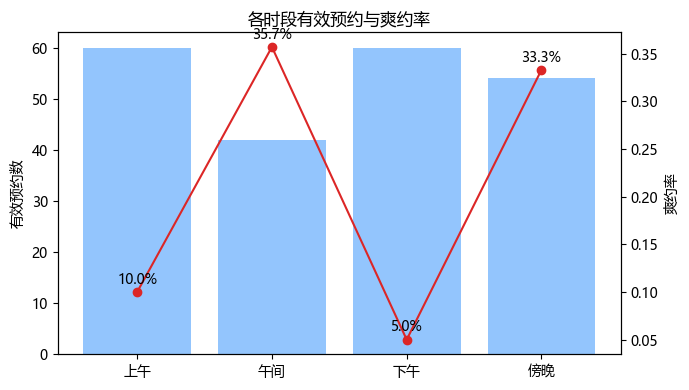

In [2]:
# 可视化 1：各时段有效预约数与爽约率
fig, ax1 = plt.subplots(figsize=(7, 4))
s = slot_summary.reindex(['上午', '午间', '下午', '傍晚'])
ax1.bar(s.index, s['有效预约数'], color='#93c5fd', label='有效预约数')
ax1.set_ylabel('有效预约数')
ax2 = ax1.twinx()
ax2.plot(s.index, s['爽约率'], color='#dc2626', marker='o', label='爽约率')
ax2.set_ylabel('爽约率')
for x, v in zip(s.index, s['爽约率']):
    ax2.annotate(f'{v:.1%}', (x, v), textcoords='offset points', xytext=(0, 6), ha='center')
plt.title('各时段有效预约与爽约率')
fig.tight_layout(); plt.show()

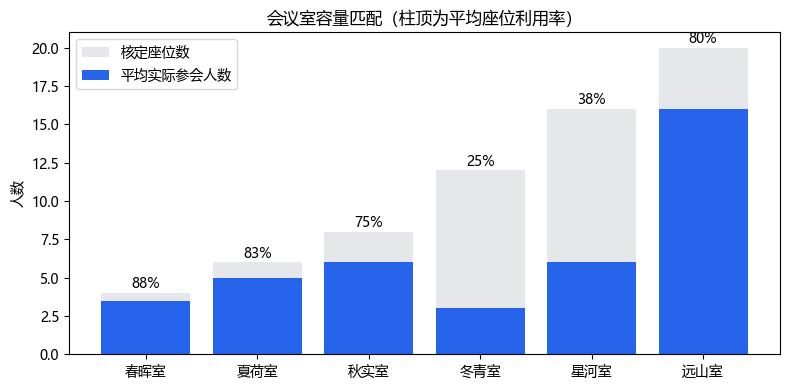

In [3]:
# 可视化 2：各会议室容量与平均参会人数、座位利用率
fig, ax = plt.subplots(figsize=(8, 4))
x = room_summary['room_name']
ax.bar(x, room_summary['capacity'], color='#e5e7eb', label='核定座位数')
ax.bar(x, room_summary['平均参会人数'], color='#2563eb', label='平均实际参会人数')
for i, u in enumerate(room_summary['平均座位利用率']):
    ax.text(i, room_summary['capacity'][i] + 0.3, f'{u:.0%}', ha='center')
ax.set_ylabel('人数'); ax.legend(); plt.title('会议室容量匹配（柱顶为平均座位利用率）')
fig.tight_layout(); plt.show()

In [4]:
# 补充：时段 × 会议室爽约率（为“智能提醒/自动释放”找重点对象）
pt = valid.pivot_table(index='room_id', columns='time_slot', values='is_no_show', aggfunc='mean').round(2)
print(pt[['上午', '午间', '下午', '傍晚']])
print('\n提前预约天数与爽约：')
valid['lead_days'] = (pd.to_datetime(valid['start_time']) - pd.to_datetime(valid['booked_at'])).dt.total_seconds() / 86400
print(valid.groupby(pd.cut(valid['lead_days'], [0, 1, 3, 30]), observed=True)['is_no_show'].agg(['count', 'mean']).round(3))

time_slot   上午    午间   下午    傍晚
room_id                        
R01        0.1  0.29  0.0  0.33
R02        0.1  0.29  0.0  0.33
R03        0.1  0.29  0.0  0.33
R04        0.1  0.43  0.1  0.33
R05        0.1  0.43  0.1  0.33
R06        0.1  0.43  0.1  0.33

提前预约天数与爽约：
           count   mean
lead_days              
(0, 1]        40  0.150
(1, 3]        72  0.208
(3, 30]      104  0.202
